# 1.5 Dimensionality reduction

A small PCA/SVD demo on the same numeric feature block used everywhere
else in this folder -- fit on the training rows only, then applied
unchanged to the test rows (the one rule every "fit on train, apply to
test" slide keeps repeating).

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
X_train, X_test = train_test_split(X, test_size=0.3, random_state=0)

# Fit the scaler AND the PCA on the training set only -- exactly the
# train/test leakage rule from Foundations 1.1/1.2 applied to a
# preprocessing step, not just to the final model.
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

pca = PCA().fit(X_train_s)
print("Explained variance ratio per component:")
print(pca.explained_variance_ratio_.round(3))
print("Cumulative:", pca.explained_variance_ratio_.cumsum().round(3))

Explained variance ratio per component:
[0.234 0.192 0.164 0.129 0.118 0.093 0.07 ]
Cumulative: [0.234 0.426 0.59  0.719 0.837 0.93  1.   ]


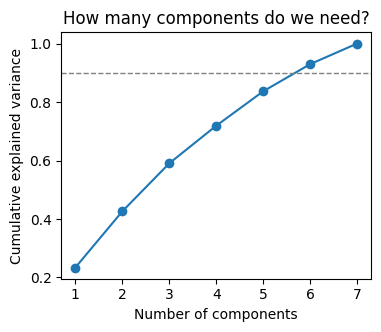

In [3]:
fig, ax = plt.subplots(figsize=(4, 3.2))
ax.plot(range(1, len(features) + 1), pca.explained_variance_ratio_.cumsum(), marker="o")
ax.axhline(0.9, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Number of components"); ax.set_ylabel("Cumulative explained variance")
ax.set_title("How many components do we need?")
plt.show()

## Loadings: which original features drive each component?

The SVD underneath PCA gives us not just the transformed coordinates but
the loadings -- how much each original feature contributes to each new
component. This is the "PCA: the math (relation to SVD)" slide made
concrete.

In [4]:
loadings = pd.DataFrame(pca.components_[:3].T, index=features, columns=["PC1", "PC2", "PC3"])
loadings.round(2)

,PC1,PC2,PC3
age,0.53,0.45,0.13
tenure_months,-0.41,0.41,0.16
income_k,0.51,0.45,0.20
monthly_usage,0.04,-0.21,0.67
support_calls,0.44,-0.43,-0.24
discount_pct,0.14,0.16,-0.61
satisfaction,-0.29,0.41,-0.20


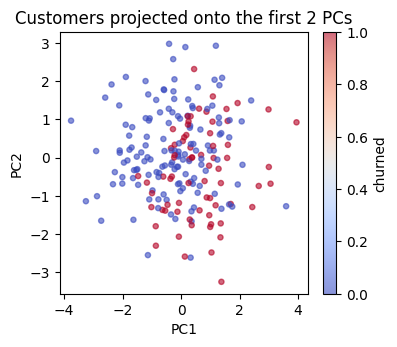

In [5]:
X_train_pca = pca.transform(X_train_s)[:, :2]
fig, ax = plt.subplots(figsize=(4, 3.4))
sc = ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], s=14, alpha=0.6,
                 c=df.loc[X_train.index, "churned"], cmap="coolwarm")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Customers projected onto the first 2 PCs")
plt.colorbar(sc, ax=ax, label="churned")
plt.show()

**Takeaway**: the first 2-3 components already recover most of the
variance in these 7 features, and PC1/PC2 alone show some visual
separation between churners and non-churners -- a hint that the *same*
churn signal used in the classification notebooks lives largely in a
low-dimensional subspace of these features.